# Task 27 — Research assistant over arXiv: find, summarise and trust the week's papers

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [arXiv Dataset](https://www.kaggle.com/datasets/Cornell-University/arxiv) — metadata for every arXiv paper (3.2 M records: title, abstract, authors, categories, versions, licence), one JSON-lines file refreshed weekly (CC0)
**Task family:** multi-label text classification, retrieval without an LLM, knowledge graph, drift · **Companion task:** `04_erp_document_rag.ipynb` (retrieval without an LLM)

---

## The task card

> **Board question.** *Our eight-person applied-AI team follows cs.CL, cs.IR, cs.LG and stat.ML. In 2026 arXiv has posted about 1,660 new papers a week in those categories, fourteen times the 120 abstracts we can read. Can an assistant route each week's papers to the right reader, find a half-remembered paper in its top five, and cite the exact version it read, so that we can trust what it tells us?*

**Business context.** Industrial research groups keep up with the literature by hand: a channel of links, a reading group, an uncurated reference manager: the legacy estate. The assistant is Session 01's *human-in-the-loop decision support* on two clocks: a weekly batch job ingests and routes new papers; an online service answers questions with citations. CC0 metadata sharpens governance: the full texts are not CC0, and the authors are people.

**What you will build from this notebook (see *Student tasks* at the end):**

1. a weekly **ingestion and routing pipeline** around the given router, packaged and reproducible, evaluated forward in time;
2. the given **retrieval pipeline**, packaged and reproducible, with a golden set in CI and a reader that cites paper *and version*;
3. an **author–paper–category–version graph**, with the ablation of plain against graph-expanded retrieval;
4. the **generation step** with claim verification (Stretch), and a one-page recommendation.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Weekly batch job plus online Q&A; licences and personal data in a CC0 dataset |
| 2 · MLOps | Pinned weekly snapshot; forward evaluation of a multi-label router; golden-set gate; drift |
| 3 · Semantic layer | Author–paper–category–version graph; author-name ambiguity; category aliases; competency questions |
| 4 · LLM/RAG | BM25 and TF-IDF, query understanding, context size and cost, claim verification |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The baseline runs **without any LLM**, so retrieval is measured before generation can hide it. Four traps are left in, measured and flagged ⚠.

**Honesty note.** The metadata is **real** and current (Kaggle version 309, newest record 23 Oct 2026). Categories are labels submitters chose, not ground truth about topic. Generated golden questions test *finding a known paper*, not whether a paper *matters* (task S3). Author names belong to real people: used inside the knowledge base, never printed.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at the weekly feed | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The router and its thresholds, BM25 retrieval and the claim check, the author–version graph and context size, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The frozen router on the moving feed, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `open_snapshot` and `build_caches` (Section 1); `text_column`, `fit_router` and `top1` (Section 3); `bm25_weights`, `make_questions`, `scores`, `answer` and `verify_claim` (Section 4); `norm_name`, `understand` and `graph_fn` (Section 5).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** router split of 30,000 training papers (seeded from 62,551), 16,271 validation and 17,020 test; test micro-F1 0.722 and macro-F1 0.530 with per-category thresholds; BM25 title-lookup recall@5 0.90 over 86,766 abstracts; at k = 5 the full pipeline's recall@5 is 0.90, 0.87 and 0.78 for the three golden families, at about €0.007 an answer.
- **Runtime:** about 2–3 minutes on a laptop once the Parquet caches exist (142 s on the build machine; building them from the raw snapshot took 11 minutes).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, zipfile, hashlib, warnings, unicodedata
from array import array
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import scipy.sparse as sp
import networkx as nx
import duckdb
from IPython.display import display
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, ENGLISH_STOP_WORDS
from sklearn.linear_model import SGDClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 80)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                  # one core per model on a shared machine; raise it on your laptop
KAGGLE_HANDLE = "Cornell-University/arxiv"
KAGGLE_VERSION = 309                        # the weekly snapshot this notebook was built from (24 Oct 2026) ...
SNAPSHOT_FILE = "arxiv-metadata-oai-snapshot.json"
SNAPSHOT_MD5 = "a1d67fb3a320b2ae47ec6cf0b0723487"   # ... and its MD5 as Kaggle publishes it
TEAM_CATS = ["cs.CL", "cs.IR", "cs.LG", "stat.ML"]  # sampling rule: every paper listed in any of these categories ...
SAMPLE_START = pd.Timestamp("2024-07-01")            # ... whose first version is on or after this date
TRAIN_END = pd.Timestamp("2025-07-01")    # router: train on Jul 2024 – Jun 2025
VALID_END = pd.Timestamp("2025-10-01")    # validation (thresholds, gate): Jul – Sep 2025
TEST_END = pd.Timestamp("2026-01-01")     # test: Oct – Dec 2025 · stream: Jan 2026 to the snapshot (Section 7)
N_TRAIN = 30_000                          # seeded sample of the training year (shrink on a small laptop)
N_LABELS = 20                             # categories the router predicts: the most frequent in training, aliases merged
INDEX_START = pd.Timestamp("2025-10-01")  # the assistant's index: every team paper first posted from here to the snapshot
GOLD_MONTH, DEV_MONTH = pd.Period("2026-09", "M"), pd.Period("2026-08", "M")   # golden questions; dev questions for tuning
N_GOLD = 300                              # questions per family
K = 5                                     # retrieval depth reported, and the abstracts the reader receives
TEAM_SIZE, ABSTRACTS_PER_PERSON_WEEK = 8, 15     # assumption: the team reads about 120 abstracts a week (task C3)
QUESTIONS_PER_WEEK = 200                  # assumption: questions put to the assistant each week (task C3)
GATE_TOLERANCE = 0.03                     # assumption: micro-F1 may fall this far below validation before retraining (C5)
TOKENS_PER_WORD = 1.35                    # English scientific prose, typical BPE tokenisers
PROMPT_OVERHEAD_TOKENS, ANSWER_TOKENS = 500, 300
EUR_PER_M_INPUT, EUR_PER_M_OUTPUT = 2.50, 10.00  # assumed model prices (task C3 replaces them with your provider's)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "arxiv", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn
print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · networkx {nx.__version__} · duckdb {duckdb.__version__} · pyarrow {pa.__version__}")

pandas 3.1.0 · scikit-learn 1.9.1 · networkx 3.7 · duckdb 2.0.0 · pyarrow 26.0.0


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `open_snapshot` and `build_caches` with the pinned MD5.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `Cornell-University/arxiv`, version 309 (24 Oct 2026), described as "a mirror of the original ArXiv data", refreshed weekly by Cornell University |
| **Licence** | Metadata CC0 1.0. Full texts: per paper (`license`); team sample: 47.9 % CC BY 4.0, 37.3 % arXiv's non-exclusive distribution licence, 5.9 % CC BY-NC-ND 4.0, 5.2 % CC BY-NC-SA 4.0 |
| **Provenance** | Real. Submitted by authors, moderated by arXiv; one record per paper, so title, abstract and categories describe one version (we take it to be the latest) |
| **Size** | 3,224,635 records (Kaggle's subtitle still says "1.7M+"), 5.65 GB of JSON lines |
| **Files** | `arxiv-metadata-oai-snapshot.json`, one record per paper; MD5 `a1d67fb3…`, pinned in the parameters |
| **Schema** | `id`, `submitter`, `authors`, `title`, `comments`, `journal-ref`, `doi`, `report-no`, `categories` (space-separated, primary first), `license`, `abstract`, `versions` (`[{version, created}]`), `update_date`, `authors_parsed` (`[surname, forenames, suffix]`) |
| **Label** | `categories`: multi-label, chosen by the submitter; 2.24 per team paper, 26 % have one |
| **Window used here** | Census: all 3.2 M records, no text. Text: **165,588** papers in the four categories first posted 1 Jul 2024 – 22 Oct 2026. Router: train Jul 2024 – Jun 2025 (seeded 30,000 of 62,551), validate Jul–Sep 2025, test Oct–Dec 2025, then the stream. Index: from 1 Oct 2025 (86,766). Golden questions: Sep 2026. Small laptop: move `SAMPLE_START` and `INDEX_START` later |
| **PII** | Author and submitter names; free-text comments. `submitter`, `comments`, `report-no` and the raw author string are dropped on load; parsed names stay for the knowledge base, never printed |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **One record per paper, many versions.** The text is one version's; `versions` holds only dates. An unversioned citation points at a moving text (Trap 3). The forward split survives it (Section 3: test micro-F1 0.720 on single-version papers, 0.724 on revised).
2. ⚠ **The weekly file is a full snapshot.** `update_date` moves when a paper is revised or edited: "updated this week" is not "new this week". (Trap 3.)
3. ⚠ **Author names are strings, not identities.** No ORCID; forenames come as initials or in full. (Trap 4.)
4. **Categories are multi-label and author-assigned**; four alias pairs always co-occur (cs.SY/eess.SY, cs.IT/math.IT, math.ST/stat.TH, math.NA/cs.NA): merge them before macro-F1.
5. **Cross-listing practice changes** (Section 7).
6. **Weekly volume swings**: the team's feed ran from 1,189 to 3,091 papers a week in 2026.
7. **Text needs normalising**: LaTeX, line breaks in titles, records without parsed authors.

**Loading.** One streaming pass (local copy, zip or kagglehub) writes two Parquet caches in chunks of 200,000 records, plus a pin file (MD5, newest `update_date`): eleven minutes here, after which the raw file can go.

In [2]:
V_FMT = "%a, %d %b %Y %H:%M:%S %Z"          # arXiv's version timestamps, e.g. "Mon, 2 Apr 2007 19:18:42 GMT"
CENSUS_COLS = ["id", "categories", "n_versions", "v1", "vlast", "update_date", "license", "has_doi", "has_jref", "n_authors"]
TEAM_COLS = ["id", "title", "abstract", "categories", "surnames", "forenames", "versions", "update_date", "license",
             "has_doi", "has_jref"]
CENSUS, TEAM, PIN = PROCESSED / "27_arxiv_census.parquet", PROCESSED / "27_arxiv_team.parquet", PROCESSED / "27_snapshot.json"


def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(f"{KAGGLE_HANDLE}/versions/{KAGGLE_VERSION}", path=filename))


def open_snapshot():
    '''The snapshot as a stream of JSON lines. A zip saved from the Kaggle page is read member-wise, never extracted.'''
    zipped = RAW / "arxiv.zip"
    if zipped.exists():
        return zipfile.ZipFile(zipped).open(SNAPSHOT_FILE)
    return open(get_raw(SNAPSHOT_FILE), "rb")


def _flush(rows, cols, writer, path):
    '''Write one chunk of records to a Parquet file; returns the open writer.'''
    df = pd.DataFrame.from_records(rows, columns=cols); rows.clear()
    to_ts = lambda s: pd.to_datetime(s, format=V_FMT, utc=True).dt.tz_localize(None).astype("datetime64[s]")
    for c in ("v1", "vlast"):
        if c in df:
            df[c] = to_ts(df[c])
    df["update_date"] = pd.to_datetime(df.update_date).astype("datetime64[s]")
    if "versions" in df:                    # team table: version timestamps as a list column, plus v1 for filtering
        lens = df.versions.map(len).to_numpy()
        flat = to_ts(pd.Series(np.concatenate(df.versions.to_numpy()))).to_numpy()
        starts = np.r_[0, lens.cumsum()]
        df = df.drop(columns="versions").assign(v1=flat[starts[:-1]])
        table = pa.Table.from_pandas(df, preserve_index=False)
        table = table.append_column("versions", pa.ListArray.from_arrays(pa.array(starts.astype("int32")), pa.array(flat)))
        table = table.filter(pa.array((df.v1 >= SAMPLE_START).to_numpy()))
    else:
        table = pa.Table.from_pandas(df, preserve_index=False)
    writer = writer or pq.ParquetWriter(path, table.schema, compression="zstd")
    writer.write_table(table)
    return writer


def build_caches():
    '''One streaming pass over the 5.6 GB file: a census of every paper (no text) and the team sample with text.'''
    t0, md5, n, newest = time.time(), hashlib.md5(), 0, ""
    team_set, first_year = set(TEAM_CATS), SAMPLE_START.year
    cen, tm, w_cen, w_tm = [], [], None, None
    with open_snapshot() as fh:
        for line in fh:
            md5.update(line); n += 1
            r = json.loads(line)
            vs, cats, ap = r["versions"], r["categories"], r.get("authors_parsed") or []
            newest = max(newest, r["update_date"])
            cen.append((r["id"], cats, len(vs), vs[0]["created"], vs[-1]["created"], r["update_date"], r.get("license"),
                        bool(r.get("doi")), bool(r.get("journal-ref")), len(ap)))
            if team_set.intersection(cats.split()) and int(vs[0]["created"].split()[3]) >= first_year:
                # governance on load: submitter, comments, report-no and the raw author string are never kept;
                # parsed surnames and forenames are kept for the knowledge base only and are never printed
                tm.append((r["id"], " ".join(r["title"].split()), " ".join(r["abstract"].split()), cats,
                           "|".join(a[0] for a in ap), "|".join(a[1] for a in ap), [v["created"] for v in vs],
                           r["update_date"], r.get("license"), bool(r.get("doi")), bool(r.get("journal-ref"))))
            if len(cen) >= 200_000:
                w_cen = _flush(cen, CENSUS_COLS, w_cen, CENSUS)
            if len(tm) >= 50_000:
                w_tm = _flush(tm, TEAM_COLS, w_tm, TEAM)
    w_cen = _flush(cen, CENSUS_COLS, w_cen, CENSUS); w_tm = _flush(tm, TEAM_COLS, w_tm, TEAM)
    w_cen.close(); w_tm.close()
    json.dump({"kaggle_version": KAGGLE_VERSION, "md5": md5.hexdigest(), "lines": n, "newest_update_date": newest,
               "built": time.strftime("%Y-%m-%d"), "seconds": round(time.time() - t0)}, open(PIN, "w"), indent=1)
    print(f"streamed {n:,} records in {time.time()-t0:.0f}s")


if not (CENSUS.exists() and TEAM.exists() and PIN.exists()):
    build_caches()
pin = json.load(open(PIN))
team = pd.read_parquet(TEAM, columns=[c for c in TEAM_COLS + ["v1"] if c not in ("title", "abstract")])   # text stays on
                                                                                                        # disk until Section 3
print(f"snapshot: Kaggle version {pin['kaggle_version']} · {pin['lines']:,} records · newest update_date {pin['newest_update_date']} · "
      f"MD5 {'matches' if pin['md5'] == SNAPSHOT_MD5 else 'DIFFERS FROM'} the pinned file · caches built in {pin['seconds'] / 60:.0f} min")
print(f"team sample: {len(team):,} papers first posted {team.v1.min():%d %b %Y} – {team.v1.max():%d %b %Y} in "
      f"{', '.join(TEAM_CATS)} · metadata {team.memory_usage(deep=True).sum()/1e6:.0f} MB in memory")

snapshot: Kaggle version 309 · 3,224,635 records · newest update_date 2026-10-23 · MD5 matches the pinned file · caches built in 11 min
team sample: 165,588 papers first posted 01 Jul 2024 – 22 Oct 2026 in cs.CL, cs.IR, cs.LG, stat.ML · metadata 52 MB in memory


## 2 · First look: a feed nobody can read

*Part A · Explore · read; the weekly volume and cross-listing shown here are signals you will monitor.*

What a team lead asks first: how much arrives each week, where, and how much belongs to one category only.

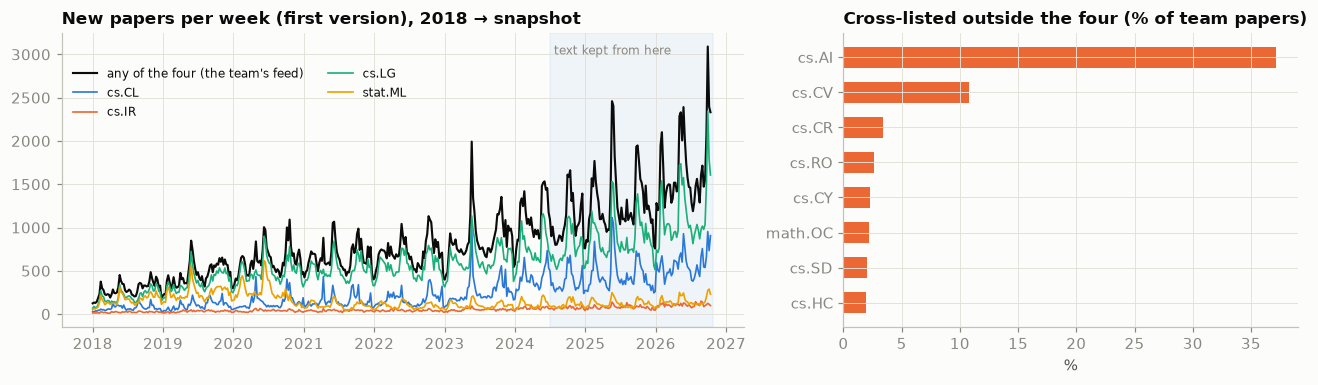

,papers / week in 2026,share of the feed
cs.CL,577,35%
cs.IR,106,6%
cs.LG,"1,141",69%
stat.ML,150,9%
any of the four,"1,661",100%


41 complete weeks in 2026, 1,189–3,091 papers a week · categories per paper: mean 2.24, single-category 26% · listed in cs.AI as well: 37%
licence of the full text (team sample): {'CC by/4.0': 47.9, 'arxiv.org/licenses/nonexclusive-distrib/1.0': 37.3, 'CC by-nc-nd/4.0': 5.9, 'CC by-nc-sa/4.0': 5.2}


In [3]:
# ---- the census, aggregated in batches: its 3.2 M rows are never in memory at once ----
FLAGS = TEAM_CATS + ["cs.AI"]
newest = pd.Timestamp(pin["newest_update_date"])
wk_parts, mo_parts, redelivered, first_parts, LAST_V1 = [], [], [], [], pd.Timestamp("1900-01-01")
for batch in pq.ParquetFile(CENSUS).iter_batches(batch_size=400_000, columns=["categories", "v1", "vlast", "update_date"]):
    d = batch.to_pandas()
    padded = " " + d.categories + " "
    f = pd.DataFrame({c: padded.str.contains(f" {c} ", regex=False) for c in FLAGS})
    f["team"] = f[TEAM_CATS].any(axis=1)
    f["cs.LG & stat.ML"], f["team & cs.AI"] = f["cs.LG"] & f["stat.ML"], f.team & f["cs.AI"]
    LAST_V1 = max(LAST_V1, d.v1.max())
    keep = d.v1 >= "2018-01-01"
    wk_parts.append(f[keep].groupby(d.v1[keep].dt.to_period("W")).sum())
    mo_parts.append(f[keep].groupby(d.v1[keep].dt.to_period("M")).sum())
    redelivered.append(d.loc[d.update_date > newest - pd.Timedelta(days=7), ["v1", "vlast"]])   # for Trap 3
    first_parts.append(d.assign(cat=d.categories.str.split()).explode("cat").groupby("cat").v1.min())   # for Section 7
weekly = pd.concat(wk_parts).groupby(level=0).sum(); weekly = weekly[weekly.index.end_time <= LAST_V1]   # complete weeks
monthly = pd.concat(mo_parts).groupby(level=0).sum(); monthly = monthly[monthly.index.end_time <= LAST_V1]
stat_share, ai_share = monthly["cs.LG & stat.ML"] / monthly["cs.LG"], monthly["team & cs.AI"] / monthly.team   # for Section 7
week_rec = pd.concat(redelivered)
first_seen = pd.concat(first_parts).groupby(level=0).min()          # first version date on which each category appears
w26 = weekly[weekly.index.start_time >= "2026-01-01"]
del wk_parts, mo_parts, redelivered, first_parts, d, f, padded

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
t_ = weekly.index.to_timestamp()
ax.plot(t_, weekly.team, color=INK, lw=1.4, label="any of the four (the team's feed)")
for c, col in zip(TEAM_CATS, SERIES):
    ax.plot(t_, weekly[c], color=col, lw=1.1, label=c)
ax.axvspan(SAMPLE_START, LAST_V1, color=SERIES[0], alpha=0.06)
ax.text(SAMPLE_START, weekly.team.max() * 0.97, " text kept from here", color=MUTED, fontsize=8)
ax.set_title("New papers per week (first version), 2018 → snapshot"); ax.legend(fontsize=8, ncol=2, loc="upper left", bbox_to_anchor=(0, 0.92))

ax = axes[1]
partners = pd.Series([c for cs in team.categories.str.split() for c in cs if c not in TEAM_CATS]).value_counts().head(8)
ax.barh(partners.index[::-1], partners.values[::-1] / len(team) * 100, color=SERIES[1], height=0.6)
ax.set_title("Cross-listed outside the four (% of team papers)"); ax.set_xlabel("%")
plt.tight_layout(); plt.show()

n_labels = team.categories.str.split().map(len)
lag = pd.DataFrame({"v1": team.v1, "v2_days": team.versions.map(lambda v: (v[1] - v[0]) / np.timedelta64(1, "D") if len(v) > 1 else np.inf)})
lic = team.license.fillna("none given").str.replace("http://", "").str.replace("creativecommons.org/licenses/", "CC ").str.rstrip("/")
first_look = pd.DataFrame({
    "papers / week in 2026": w26[TEAM_CATS + ["team"]].mean(),
    "share of the feed": w26[TEAM_CATS + ["team"]].mean() / w26.team.mean(),
}).rename(index={"team": "any of the four"})
display(first_look.style.format({"papers / week in 2026": "{:,.0f}", "share of the feed": "{:.0%}"}))
print(f"{len(w26)} complete weeks in 2026, {w26.team.min():,}–{w26.team.max():,} papers a week · categories per paper: mean {n_labels.mean():.2f}, "
      f"single-category {(n_labels == 1).mean():.0%} · listed in cs.AI as well: {team.categories.str.contains('cs.AI', regex=False).mean():.0%}")
print("licence of the full text (team sample):", (lic.value_counts(normalize=True).head(4) * 100).round(1).to_dict())
team = team.drop(columns=["license", "has_doi", "has_jref", "update_date"])

In 2026 the four categories post about 1,660 papers a week, 69 % in cs.LG. Three papers in four carry several categories; 37 % are also in cs.AI. And before anyone proposes to "just index the PDFs": only half the full texts are CC BY.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Routing: which readers should see a new paper?

*Part B · Given model · package `text_column`, `fit_router` and `top1` unchanged; C3 owns the per-category thresholds.*

Each reader owns a category, and the weekly job sends every new paper to each reader whose category it carries: multi-label classification from title and abstract. Labels are the submitters' categories, aliases merged; the 20 most frequent cover 88 % of training assignments. Train on July 2024 – June 2025, set thresholds on July – September 2025, report on October – December 2025. The baseline is TF-IDF with one logistic model per category, trained by SGD in seconds.

In [4]:
# ---- labels: author-assigned categories, with arXiv's aliases merged (they always appear together) ----
ALIASES = {"eess.SY": "cs.SY", "math.IT": "cs.IT", "stat.TH": "math.ST", "cs.NA": "math.NA", "math-ph": "math.MP", "q-fin.EC": "econ.GN"}
cats_split = team.categories.str.split()
alias_pairs = {f"{a} / {b}": (cats_split.map(lambda cs: a in cs) == cats_split.map(lambda cs: b in cs)).mean()
               for a, b in [("eess.SY", "cs.SY"), ("math.IT", "cs.IT"), ("stat.TH", "math.ST"), ("cs.NA", "math.NA")]}
team["labels"] = cats_split.map(lambda cs: sorted({ALIASES.get(c, c) for c in cs}))
team["primary"] = cats_split.str[0].map(lambda c: ALIASES.get(c, c))
print("papers on which each alias pair agrees (both or neither):", {k: f"{v:.2%}" for k, v in alias_pairs.items()})

# ---- forward split; the training year is sampled once, here, so that tokenising fits a laptop's budget ----
period_of = lambda t: np.select([t < TRAIN_END, t < VALID_END, t < TEST_END], ["train", "valid", "test"], "stream")
train_rows = np.flatnonzero(period_of(team.v1.to_numpy()) == "train")
label_counts = pd.Series([c for ls in team.labels.iloc[train_rows] for c in ls]).value_counts()   # the whole training year
LABELS = label_counts.index[:N_LABELS].tolist()
keep_mask = np.ones(len(team), dtype=bool)
keep_mask[np.setdiff1d(train_rows, rng.choice(train_rows, N_TRAIN, replace=False))] = False
team = team[keep_mask].reset_index(drop=True)
v1 = team.v1.to_numpy(); period = period_of(v1)
tr, va, te = (np.flatnonzero(period == p) for p in ("train", "valid", "test"))
Y = np.array([[c in set(ls) for c in LABELS] for ls in team.labels], dtype=np.int8)
print(f"train {len(tr):,} of {len(train_rows):,} (seeded sample) · valid {len(va):,} · test {len(te):,} · stream {np.sum(period == 'stream'):,}")
print(f"{N_LABELS} labels cover {label_counts.iloc[:N_LABELS].sum() / label_counts.sum():.1%} of training category assignments; "
      f"the rarest kept: {LABELS[-1]} ({label_counts.iloc[N_LABELS - 1]:,} training papers)")

# ---- tokenise once; every later view (router features, indexes, drift) is a slice of these counts ----
TOKEN = r"(?u)\b[^\W\d_][\w\-]*\w\b"     # words starting with a letter, incl. digits and hyphens (gpt-4); no bare numbers
STOP = sorted(ENGLISH_STOP_WORDS)
t0 = time.time()
analyse = CountVectorizer(token_pattern=TOKEN, stop_words=STOP).build_analyzer()   # lower-case, tokenise, drop stop words

class Counts:
    '''Sparse term counts in one pass, in compact C arrays; the term list grows as documents arrive.'''
    def __init__(self):
        self.vocab = {}
    def _count(self, docs, grow):
        indptr, indices, data = array("q", [0]), array("i"), array("f")
        lookup = self.vocab.setdefault if grow else self.vocab.get
        for d in docs:
            c = Counter(lookup(t, len(self.vocab)) if grow else lookup(t) for t in analyse(d))
            c.pop(None, None)
            indices.extend(c.keys()); data.extend(c.values()); indptr.append(len(indices))
        return sp.csr_matrix((np.frombuffer(data, np.float32), np.frombuffer(indices, np.int32), np.frombuffer(indptr, np.int64)),
                             shape=(len(indptr) - 1, len(self.vocab)))
    def fit_transform(self, docs):
        return self._count(docs, grow=True)
    def transform(self, docs):
        return self._count(docs, grow=False)

def text_column(column, mask, batch=20_000):
    '''Stream one text column from the Parquet cache, yielding the rows in `mask`: the text is never held whole.'''
    at = 0
    for b in pq.ParquetFile(TEAM).iter_batches(batch_size=batch, columns=[column]):
        values = b.column(0).to_pylist(); m = mask[at:at + len(values)]; at += len(values)
        yield from (v for v, k in zip(values, m) if k)

counts = Counts()
C_tit = counts.fit_transform(text_column("title", keep_mask))     # one term list for titles and abstracts; it spans all
C_abs = counts.fit_transform(text_column("abstract", keep_mask))  # periods, but the router uses only training terms and IDF
C_tit.resize(C_abs.shape)
C_all = (C_tit + C_abs).tocsr(); del C_tit
print(f"{C_all.shape[0]:,} papers × {len(counts.vocab):,} terms, {C_all.nnz/1e6:.1f} M non-zeros, tokenised in {time.time()-t0:.0f}s")

papers on which each alias pair agrees (both or neither): {'eess.SY / cs.SY': '100.00%', 'math.IT / cs.IT': '100.00%', 'stat.TH / math.ST': '100.00%', 'cs.NA / math.NA': '100.00%'}


train 30,000 of 62,551 (seeded sample) · valid 16,271 · test 17,020 · stream 69,746
20 labels cover 88.4% of training category assignments; the rarest kept: cs.NE (816 training papers)


133,037 papers × 351,398 terms, 12.5 M non-zeros, tokenised in 26s


In [5]:
df_train = np.bincount(C_all[tr].indices, minlength=C_all.shape[1])
KEEP = np.flatnonzero(df_train >= 5)                       # the router's vocabulary: terms in ≥ 5 training papers
tfidf_router = TfidfTransformer(sublinear_tf=True).fit(C_all[tr][:, KEEP])
features = lambda rows: tfidf_router.transform(C_all[rows][:, KEEP])

def fit_router(rows):
    clf = SGDClassifier(loss="log_loss", alpha=2e-5, max_iter=20, tol=None, random_state=SEED)
    return OneVsRestClassifier(clf, n_jobs=N_JOBS).fit(features(rows), Y[rows])

t0 = time.time()
router = fit_router(tr)
P_va, P_te = router.predict_proba(features(va)), router.predict_proba(features(te))
print(f"{len(KEEP):,} terms · {N_LABELS} one-vs-rest logistic models fitted in {time.time()-t0:.0f}s")

GRID = np.round(np.arange(0.05, 0.951, 0.025), 3)
thr_label = np.array([GRID[np.argmax([f1_score(Y[va, j], P_va[:, j] >= g, zero_division=0) for g in GRID])] for j in range(N_LABELS)])
thr_global = GRID[np.argmax([f1_score(Y[va], P_va >= g, average="micro") for g in GRID])]

def top1(P):
    out = np.zeros(P.shape, dtype=np.int8); out[np.arange(len(P)), P.argmax(1)] = 1
    return out

POLICIES = {"top-1 only (single-label)": lambda P: top1(P), "0.5 for every category": lambda P: P >= 0.5,
            f"one threshold ({thr_global:.2f}, best micro-F1 on validation)": lambda P: P >= thr_global,
            "per-category thresholds (best F1 each, on validation)": lambda P: P >= thr_label}
rows = []
for name, rule in POLICIES.items():
    for split, P, idx_ in [("validation", P_va, va), ("test", P_te, te)]:
        pred = rule(P)
        rows.append({"policy": name, "split": split, "micro-F1": f1_score(Y[idx_], pred, average="micro"),
                     "macro-F1": f1_score(Y[idx_], pred, average="macro", zero_division=0), "labels / paper": pred.sum(1).mean()})
policy_tbl = pd.DataFrame(rows).pivot(index="policy", columns="split").reindex(list(POLICIES))
display(policy_tbl.style.format("{:.3f}"))
print(f"true labels per paper (test): {Y[te].sum(1).mean():.2f}")
# the file holds each paper's latest text and categories: does a forward split suffer from that?
n_versions = team.versions.map(len).to_numpy()
revised = (team.versions.map(lambda v: v[-1]).to_numpy()[tr] >= np.datetime64(TRAIN_END)).mean()
f1_v = {k_: f1_score(Y[te][m_], (P_te >= thr_label)[m_], average="micro") for k_, m_ in
        [("single-version", n_versions[te] == 1), ("revised", n_versions[te] > 1)]}
print(f"{revised:.1%} of training papers were revised after the training cut; test micro-F1 (per-category thresholds): "
      f"single-version papers {f1_v['single-version']:.3f}, revised papers {f1_v['revised']:.3f}")

17,889 terms · 20 one-vs-rest logistic models fitted in 10s


true labels per paper (test): 1.91
23.1% of training papers were revised after the training cut; test micro-F1 (per-category thresholds): single-version papers 0.720, revised papers 0.724


**The operating point is a threshold per reader.** One category per paper, as a single-label classifier predicts, gives micro-F1 0.61 (Trap 1). A 0.5 threshold is too strict: 1.6 labels predicted per paper against 1.9 true. One tuned threshold gives the best micro-F1 (0.726); per-category thresholds the best macro-F1 (0.530), routing 2.35 labels per paper. With one IR reader, small categories matter more than a point of micro-F1, so per-category thresholds are the operating point.

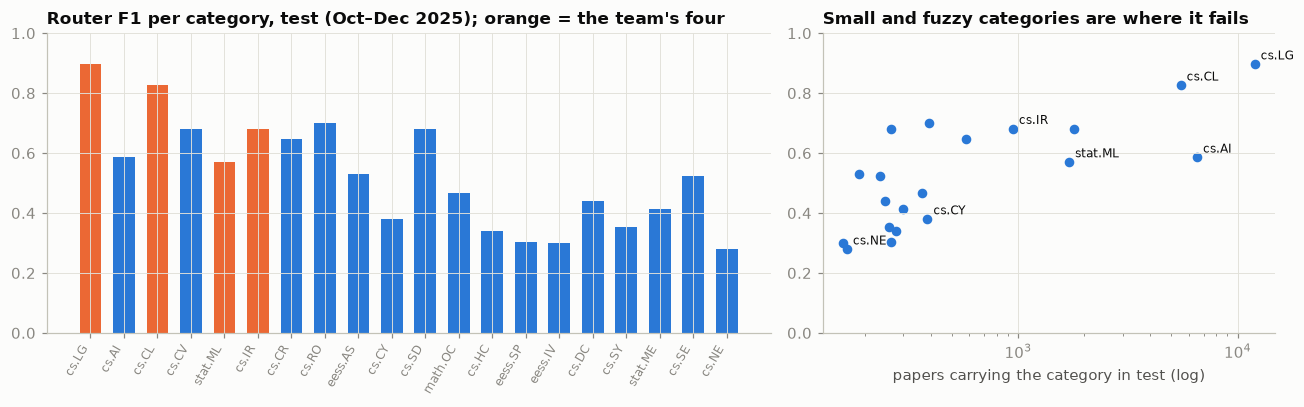

,support (test),F1,precision,recall,threshold,true papers / week,routed / week
cs.CL,"5,503",0.827,0.774,0.886,0.400,419,479
cs.IR,947,0.682,0.711,0.655,0.250,72,66
cs.LG,"11,962",0.897,0.887,0.907,0.550,910,931
stat.ML,"1,708",0.570,0.535,0.611,0.300,130,149
cs.AI,"6,533",0.586,0.454,0.827,0.250,—,—


reading capacity assumed: 120 abstracts a week for the whole team


In [6]:
PRED_te = P_te >= thr_label
per_label = pd.DataFrame({"support (test)": Y[te].sum(0), "F1": f1_score(Y[te], PRED_te, average=None, zero_division=0),
                          "precision": [(PRED_te[:, j] & Y[te, j]).sum() / max(PRED_te[:, j].sum(), 1) for j in range(N_LABELS)],
                          "recall": [(PRED_te[:, j] & Y[te, j]).sum() / max(Y[te, j].sum(), 1) for j in range(N_LABELS)],
                          "threshold": thr_label}, index=LABELS)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
x = np.arange(N_LABELS)
ax.bar(x, per_label.F1, color=[SERIES[1] if c in TEAM_CATS else SERIES[0] for c in LABELS], width=0.65)
ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=8); ax.set_ylim(0, 1)
ax.set_title("Router F1 per category, test (Oct–Dec 2025); orange = the team's four")
ax = axes[1]
ax.scatter(per_label["support (test)"], per_label.F1, s=28, color=SERIES[0])
for c in ["cs.LG", "cs.CL", "cs.AI", "cs.IR", "stat.ML", "cs.CY", "cs.NE"]:
    if c in per_label.index:
        ax.annotate(c, (per_label.loc[c, "support (test)"], per_label.loc[c, "F1"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_ylim(0, 1); ax.set_xlabel("papers carrying the category in test (log)")
ax.set_title("Small and fuzzy categories are where it fails")
plt.tight_layout(); plt.show()

test_weeks = (TEST_END - VALID_END).days / 7
load = pd.DataFrame({"true papers / week": Y[te][:, [LABELS.index(c) for c in TEAM_CATS]].sum(0) / test_weeks,
                     "routed / week": PRED_te[:, [LABELS.index(c) for c in TEAM_CATS]].sum(0) / test_weeks}, index=TEAM_CATS)
display(pd.concat([per_label.loc[TEAM_CATS + ["cs.AI"]], load], axis=1).style.format(
    {"support (test)": "{:,.0f}", "F1": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "threshold": "{:.3f}",
     "true papers / week": "{:,.0f}", "routed / week": "{:,.0f}"}, na_rep="—"))
print(f"reading capacity assumed: {TEAM_SIZE * ABSTRACTS_PER_PERSON_WEEK} abstracts a week for the whole team")

Large, coherent categories route well (cs.LG 0.90, cs.CL 0.83); cs.IR reaches 0.68, stat.ML 0.57, and cs.AI, which authors add most loosely, 0.59 at precision 0.45. The load table is the uncomfortable part: about 66 papers a week for the cs.IR reader and 930 for cs.LG, against 15 a reader. Routing narrows the feed; it does not decide what matters (task S3).

## 4 · Finding a paper: retrieval without an LLM

*Part B · Given model · package `bm25_weights`, `make_questions`, `scores`, `answer` and `verify_claim`; the golden set becomes C4's gate.*

The second request is *find me that paper*. As in Task 04, the index holds one document per paper (its abstract), retrieval is BM25 or TF-IDF, and the golden set is generated from the data. Three families from papers first posted in September 2026 (the last complete month), against every team paper since October 2025:

- **title lookup**: the question is the title; the index holds abstracts only (Trap 2 shows why);
- **remembered paper**: "the 2026 paper by ‹first author› about ‹three title words›", as people actually ask;
- **remembered, one detail wrong**: the same with the year one too early, a co-author's name or a misspelt surname; memory is noisy, and Section 5's graph links exactly these fields.

BM25 is one sparse matrix product, tested against `rank_bm25` before it is trusted.

In [7]:
in_idx = np.flatnonzero(v1 >= INDEX_START)
text = pd.read_parquet(TEAM, columns=["id", "title", "abstract"], filters=[("v1", ">=", INDEX_START)])
assert (text.id.to_numpy() == team.id.to_numpy()[in_idx]).all()          # same papers, same order
idx = pd.concat([team.iloc[in_idx].reset_index(drop=True), text[["title", "abstract"]]], axis=1)
A = C_abs[in_idx]; del C_abs, text                  # the honest index: abstracts only (Trap 2 shows why)

def bm25_weights(C, k1=1.5, b=0.75, eps=0.25):
    '''BM25 (Okapi, as rank_bm25 computes it) as a sparse document × term matrix: score = W @ query_counts.'''
    C = C.tocsr().astype(np.float32); n = C.shape[0]
    df = np.bincount(C.indices, minlength=C.shape[1])
    idf = np.log(n - df + 0.5) - np.log(df + 0.5)
    idf = np.where(idf < 0, eps * idf.mean(), idf)
    dl = np.asarray(C.sum(1)).ravel(); row = np.repeat(np.arange(n), np.diff(C.indptr))
    W = C.copy(); W.data = (idf[C.indices] * C.data * (k1 + 1) / (C.data + k1 * (1 - b + b * dl[row] / dl.mean()))).astype(np.float32)
    return W

t0 = time.time()
W_abs = bm25_weights(A)
tfidf_idx = TfidfTransformer(sublinear_tf=True).fit(A); T_abs = tfidf_idx.transform(A).astype(np.float32)
# a test, not a hope: the sparse version must equal the reference implementation
sub = idx.abstract.iloc[:2000]
ref, W_sub = BM25Okapi([analyse(t) for t in sub]), bm25_weights(counts.transform(sub))
q_tok = analyse(idx.title.iloc[0])
max_diff = np.abs((W_sub @ counts.transform([" ".join(q_tok)]).T).toarray().ravel() - ref.get_scores(q_tok)).max()
print(f"index: {len(idx):,} abstracts ({INDEX_START:%d %b %Y} → {idx.v1.max():%d %b %Y}), {A.nnz/1e6:.1f} M postings, built in {time.time()-t0:.0f}s")
print(f"sparse BM25 vs rank_bm25 on 2,000 abstracts: max |difference| = {max_diff:.1e}")

index: 86,766 abstracts (01 Oct 2025 → 22 Oct 2026), 8.2 M postings, built in 1s
sparse BM25 vs rank_bm25 on 2,000 abstracts: max |difference| = 1.1e-06


In [8]:
idx["month"] = idx.v1.dt.to_period("M")
pos = pd.Series(np.arange(len(idx)), index=idx.id)

def make_questions(month, n, seed):
    '''Three families with exact answers: a title lookup; a remembered paper (first author, year, three title words);
    and the same paper remembered with one detail wrong (year one too early, a co-author's name, or a misspelt surname).'''
    r, r_err = np.random.default_rng(seed), np.random.default_rng(seed + 100)
    rows = []
    for j, p in enumerate(idx[idx.month == month].sample(n, random_state=seed).itertuples()):
        rows.append({"family": "title lookup", "question": p.title, "target": pos[p.id], "surname": "", "error": ""})
        words = [w for w in re.findall(r"[A-Za-z][A-Za-z\-]{3,}", p.title) if w.lower() not in ENGLISH_STOP_WORDS]
        names = p.surnames.split("|"); sur = names[0]
        if words and sur:
            kw = " ".join(r.choice(words, min(3, len(words)), replace=False))
            rows.append({"family": "remembered paper", "question": f"the {p.v1.year} paper by {sur} about {kw}",
                         "target": pos[p.id], "surname": sur, "error": ""})
            error = ["year one too early", "a co-author's name", "surname misspelt"][j % 3]
            if (error == "a co-author's name" and len(names) < 2) or (error == "surname misspelt" and len(sur) < 4):
                error = "year one too early"                  # (a later year would be in the future: nobody misremembers that way)
            yr, name = p.v1.year, sur
            if error == "year one too early":
                yr -= 1
            elif error == "a co-author's name":
                name = names[1 + r_err.integers(len(names) - 1)]
            else:                                             # drop one inner letter
                i = 1 + r_err.integers(len(sur) - 2); name = sur[:i] + sur[i + 1:]
            rows.append({"family": "remembered, one detail wrong", "question": f"the {yr} paper by {name} about {kw}",
                         "target": pos[p.id], "surname": name, "error": error})
    return pd.DataFrame(rows)

gold, dev = make_questions(GOLD_MONTH, N_GOLD, SEED), make_questions(DEV_MONTH, N_GOLD, SEED + 1)
FAMILIES = ["title lookup", "remembered paper", "remembered, one detail wrong"]
show = gold.groupby("family").head(2).copy()
show["question"] = [q.replace(s, "‹author›") if s else q for q, s in zip(show.question, show.surname)]   # no names in outputs
GOLD_SHA256 = hashlib.sha256(gold[["family", "question"]].assign(id=idx.id[gold.target].values).to_csv(index=False).encode()).hexdigest()
print(f"golden set: {len(gold)} questions from {GOLD_MONTH} papers {gold.family.value_counts().to_dict()} · dev set {len(dev)} from {DEV_MONTH}"
      f" · golden-set SHA-256 {GOLD_SHA256[:16]}…\nthe wrong detail: {gold.error[gold.error != ''].value_counts().to_dict()}")
display(show[["family", "question", "error"]])

golden set: 900 questions from 2026-09 papers {'title lookup': 300, 'remembered paper': 300, 'remembered, one detail wrong': 300} · dev set 900 from 2026-08 · golden-set SHA-256 61dd0dd769148cae…
the wrong detail: {'year one too early': 139, "a co-author's name": 89, 'surname misspelt': 72}


,family,question,error
0,title lookup,When Is an SAE Feature Interpretable? A Validation Ladder for EEG Foundation...,
1,remembered paper,the 2026 paper by ‹author› about Feature Interpretable Ladder,
2,"remembered, one detail wrong",the 2025 paper by ‹author› about Feature Interpretable Ladder,year one too early
3,title lookup,"""very likely"" Means ""uncertain""? How LLMs Diverge from Humans in Linguistic ...",
4,remembered paper,the 2026 paper by ‹author› about Means uncertain LLMs,
5,"remembered, one detail wrong",the 2026 paper by ‹author› about Means uncertain LLMs,a co-author's name


In [9]:
def scores(M, transform, questions, batch=100):
    '''Dense document × question score matrix, in batches.'''
    for s in range(0, len(questions), batch):
        Q = transform(list(questions[s:s + batch]))
        yield s, (M @ Q.T).toarray()

def ranks_of(score_fn, qs):
    '''Pessimistic rank of the target (ties count against it), one per question.'''
    out = np.zeros(len(qs), dtype=int); tgt = qs.target.to_numpy()
    for s, S in score_fn(qs.question.tolist()):
        j = np.arange(S.shape[1]); t = S[tgt[s:s + S.shape[1]], j]
        out[s:s + S.shape[1]] = (S >= t).sum(0)
    return out

def summarise(rk, qs, k=K):
    d = pd.DataFrame({"family": qs.family.values, "recall@1": rk <= 1, f"recall@{k}": rk <= k, "MRR": 1 / rk})
    return d.groupby("family").mean().reindex(FAMILIES)

bm25_fn = lambda W: (lambda qs: scores(W, counts.transform, qs))
tfidf_fn = lambda qs: scores(T_abs, lambda q: tfidf_idx.transform(counts.transform(q)), qs)

def top_ranks(S, depth=1000):
    '''Rank of each document in each column's top `depth` (1 = best); documents below it get no rank (inf).'''
    top = np.argpartition(-S, depth, axis=0)[:depth]
    order = np.take_along_axis(top, np.argsort(-np.take_along_axis(S, top, 0), axis=0, kind="stable"), 0)
    R = np.full(S.shape, np.inf, dtype=np.float32)
    np.put_along_axis(R, order, np.arange(1, depth + 1, dtype=np.float32)[:, None], 0)
    return R

def rrf_fn(fn_a, fn_b, k=60):
    def run(qs):
        for (s, Sa), (_, Sb) in zip(fn_a(qs), fn_b(qs)):
            yield s, 1 / (k + top_ranks(Sa)) + 1 / (k + top_ranks(Sb))
    return run

RETRIEVERS = {"BM25 · abstracts": bm25_fn(W_abs), "TF-IDF cosine · abstracts": tfidf_fn,
              "hybrid (RRF of the two)": rrf_fn(bm25_fn(W_abs), tfidf_fn)}
t0 = time.time()
RANKS = {name: ranks_of(fn, gold) for name, fn in RETRIEVERS.items()}
board = pd.concat({name: summarise(rk, gold) for name, rk in RANKS.items()}, names=["retriever", "family"])
print(f"{len(RETRIEVERS)} retrievers × {len(gold)} questions over {len(idx):,} abstracts in {time.time()-t0:.0f}s")
board.unstack("family").style.format("{:.2f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

3 retrievers × 900 questions over 86,766 abstracts in 13s


In [10]:
# ---- the reader: cite the exact version, quote the best-matching sentence; no generation ----
n_ver = idx.versions.map(len).to_numpy()

def answer(question, k=K):
    '''Retrieve with BM25, cite the top paper at the version the index holds, and quote its best-matching sentence.'''
    s = (W_abs @ counts.transform([question]).T).toarray().ravel()
    top = np.argsort(-s)[:k]
    p, q_terms = idx.iloc[top[0]], set(analyse(question))
    sentences = re.split(r"(?<=[.!?])\s+", p.abstract)
    best = max(sentences, key=lambda t: len(q_terms & set(analyse(t))))
    return {"cite": f"arXiv:{p.id}v{n_ver[top[0]]}", "version posted": f"{pd.Timestamp(p.versions[-1]):%Y-%m-%d}", "title": p.title,
            "evidence": best[:220], "as of snapshot": pin["newest_update_date"], "also retrieved": [idx.id[i] for i in top[1:]]}

for g in gold[gold.family == "title lookup"].head(2).itertuples():
    a = answer(g.question)
    print(json.dumps({"question": g.question[:90], "correct": a["cite"].rsplit("v", 1)[0] == f"arXiv:{idx.id[g.target]}", **a}, indent=1)[:900], "\n")

{
 "question": "When Is an SAE Feature Interpretable? A Validation Ladder for EEG Foundation Models",
 "correct": true,
 "cite": "arXiv:2609.34091v1",
 "version posted": "2026-09-28",
 "title": "When Is an SAE Feature Interpretable? A Validation Ladder for EEG Foundation Models",
 "evidence": "In EEG foundation models, this creates a tempting inference: if removing alpha-band activity strongly changes a latent's activation, one might conclude that the latent represents alpha activity.",
 "as of snapshot": "2026-10-23",
 "also retrieved": [
  "2605.01829",
  "2603.01752",
  "2603.04478",
  "2606.08583"
 ]
} 

{
 "question": "\"very likely\" Means \"uncertain\"? How LLMs Diverge from Humans in Linguistic Uncertainty Qu",
 "correct": true,
 "cite": "arXiv:2610.00083v1",
 "version posted": "2026-09-06",
 "title": "\"very likely\" Means \"uncertain\"? How LLMs Diverge from Humans in Linguistic Uncertainty Quantification",
 "evidence": "In this paper, we investigate how LLMs diverge from hum

BM25 finds the paper from its title 80 % of the time at rank 1 and 90 % in the top five. TF-IDF is worse, and fusing the two (RRF) lands in between: fusion is not free. Remembered papers are much harder (0.36 in both families): a surname and three title words are not what an abstract says. The reader cites the paper **with** its version and quotes the matching sentence; it never paraphrases.

### Trust: can a claim be checked against the cited abstract?

Before any LLM writes an answer (Stretch S1), decide how its claims are checked. `verify_claim` accepts a claim if a share τ of its content words occurs in the cited abstract, with every number, and any negation ("not", "no", "without") also occurs in the best-matching sentence. Of six test kinds, the paper's own title is an honest paraphrase, and a sentence with a third of its words dropped passes by construction (a sanity check only); τ is chosen on August to separate a paper's title from the runner-up's.

In [11]:
# ---- trust: a deterministic claim verifier the generation step will have to pass (Stretch S1 builds on it) ----
NUM = re.compile(r"\d+(?:\.\d+)?")
NEGATIONS = {"not", "no", "nor", "never", "none", "cannot", "without"}
analyse_claim = CountVectorizer(token_pattern=TOKEN, stop_words=sorted(ENGLISH_STOP_WORDS - NEGATIONS)).build_analyzer()   # keeps "not"

def claim_evidence(claim, abstract):
    '''Share of the claim's content words found in the cited abstract; whether its numbers are there; whether any
    negation in it also appears in the abstract sentence that matches it best.'''
    c_terms = set(analyse_claim(claim))
    coverage = len(c_terms & set(analyse_claim(abstract))) / max(len(c_terms), 1)
    best = max(re.split(r"(?<=[.!?])\s+", abstract), key=lambda t: len(c_terms & set(analyse_claim(t))))
    return coverage, set(NUM.findall(claim)) <= set(NUM.findall(abstract)), (c_terms & NEGATIONS) <= set(analyse_claim(best))

def verify_claim(claim, abstract, tau):
    coverage, numbers_ok, negation_ok = claim_evidence(claim, abstract)
    return coverage >= tau and numbers_ok and negation_ok

def claim_set(qs, seed):
    '''Claims about each title question's target: two true kinds and four false ones, the closest being from the runner-up.'''
    r = np.random.default_rng(seed); out = []
    tq = qs[qs.family == "title lookup"].reset_index(drop=True)
    sentences = lambda text: [x for x in re.split(r"(?<=[.!?])\s+", text) if len(x.split()) >= 12] or [text]
    for s, S in scores(W_abs, counts.transform, tq.question.tolist()):
        for j in range(S.shape[1]):
            tgt = tq.target[s + j]
            sent = (ss := sentences(idx.abstract[tgt]))[r.integers(len(ss))]; w = sent.split()
            keep = np.sort(r.choice(len(w), int(len(w) * 2 / 3), replace=False))
            top3 = np.argpartition(-S[:, j], 3)[:3]
            other = [i for i in top3[np.argsort(-S[top3, j])] if i != tgt][0]           # the closest *other* paper
            out.append(("true · the paper's own title", idx.title[tgt], tgt))
            out.append(("true · an abstract sentence, a third of its words dropped (passes by construction)", " ".join(w[i] for i in keep), tgt))
            out.append(("wrong paper · the runner-up's title", idx.title[other], tgt))
            out.append(("wrong paper · a runner-up sentence", (os_ := sentences(idx.abstract[other]))[r.integers(len(os_))], tgt))
            if nums := NUM.findall(sent):
                out.append(("number changed", sent.replace(nums[0], str(int(float(nums[0])) + 7), 1), tgt))
            if " is " in sent or " are " in sent:
                out.append(("negation inserted", sent.replace(" is ", " is not ", 1).replace(" are ", " are not ", 1), tgt))
    out = pd.DataFrame(out, columns=["kind", "claim", "target"])
    ev = [claim_evidence(c, idx.abstract[t]) for c, t in zip(out.claim, out.target)]
    return out.assign(coverage=[e[0] for e in ev], rules_ok=[e[1] and e[2] for e in ev])

claims_dev, claims_gold = claim_set(dev, SEED), claim_set(gold, SEED + 1)
accept = lambda cl, tau: ((cl.coverage >= tau) & cl.rules_ok).groupby(cl.kind).mean()
# τ: the best separation, on the August questions, of a paper's own title from the runner-up's title
taus = np.round(np.arange(0.3, 0.96, 0.05), 2)
sep = [accept(claims_dev, t)["true · the paper's own title"] - accept(claims_dev, t)["wrong paper · the runner-up's title"] for t in taus]
TAU = float(taus[int(np.argmax(sep))])
verifier = accept(claims_gold, TAU).to_frame(f"accepted (τ = {TAU}, chosen on dev)")
verifier["claims"] = claims_gold.kind.value_counts()
display(verifier.style.format({verifier.columns[0]: "{:.1%}", "claims": "{:d}"}))

,"accepted (τ = 0.55, chosen on dev)",claims
kind,,
negation inserted,9.1%,66
number changed,6.3%,63
"true · an abstract sentence, a third of its words dropped (passes by construction)",100.0%,300
true · the paper's own title,83.0%,300
wrong paper · a runner-up sentence,1.3%,300
wrong paper · the runner-up's title,8.7%,300


At τ = 0.55 the verifier accepts 83 % of the papers' own titles, but also 8.7 % of runner-up titles, 1.3 % of runner-up sentences, 6.3 % of changed numbers and 9.1 % of inserted negations (where the matching sentence already held one). Rejecting one honest paraphrase in six and passing one near miss in eleven is the price of lexical checking; S1's NLI or judge model must beat both.

## 5 · The knowledge base: authors, categories and versions as a graph

*Part B · Given model · package `norm_name`, `understand` and `graph_fn`; E1 extends this ablation, C3 owns the context size.*

A remembered paper is described by a person and a year, which the abstract index does not hold; the knowledge layer links them. Four edge tables (a Neo4j bulk-import shape) answer competency questions no retriever can: which version to cite on a date, who has published in cs.IR before, what arrived last week. Three contract checks (task E3's SHACL shapes) run on every build.

In [12]:
def norm_name(s: str) -> str:
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", s)).strip()

# ---- four edge tables: the shape a property-graph bulk import (Neo4j) takes ----
papers = idx[["id", "title", "v1", "primary"]].assign(n_versions=n_ver)
versions = (idx[["id", "versions"]].explode("versions").rename(columns={"versions": "created"})
            .assign(created=lambda d: pd.to_datetime(d.created), v=lambda d: d.groupby("id").cumcount() + 1))
authorship = idx[["id"]].assign(surname=idx.surnames.str.split("|"), forename=idx.forenames.str.split("|")).explode(["surname", "forename"])
authorship["pos"] = authorship.groupby("id").cumcount()
authorship["sn"] = authorship.surname.map(norm_name)
fn = authorship.forename.fillna("").map(norm_name)
authorship["key_naive"] = authorship.sn + "," + fn.str[:1]                 # surname + first initial
authorship["key_strict"] = authorship.sn + "," + fn                       # surname + full forename(s)
authorship["initials_only"] = authorship.forename.fillna("").str.fullmatch(r"(?:[A-Z]\.?[\s\-]*)+")
categories = idx[["id", "labels", "primary"]].explode("labels").rename(columns={"labels": "category"})
categories["is_primary"] = categories.category == categories.primary

# ---- contract checks a pipeline stage would run (the SHACL shapes of task E3) ----
checks = {
    "papers with version dates out of order": versions.id[(versions.created.diff() < pd.Timedelta(0)) & (versions.v > 1)].nunique(),
    "papers whose primary category is not among its categories": int((~categories.groupby("id").is_primary.any()).sum()),
    "author rows with an empty surname": int((authorship.sn == "").sum()),
}
print(f"graph: {len(papers):,} papers · {len(versions):,} versions · {len(authorship):,} authorships "
      f"({authorship.key_strict.nunique():,} strict author keys) · {len(categories):,} paper–category edges")
print("contract checks:", checks)

# ---- competency questions the graph answers and retrieval cannot ----
con = duckdb.connect()
for name, frame in {"papers": papers, "versions": versions, "authorship": authorship[["id", "pos", "sn", "key_strict"]],
                    "categories": categories[["id", "category", "is_primary"]]}.items():
    con.register(name, frame)
ex = papers[papers.n_versions >= 3].iloc[0]
cq = {
    "CQ1 · which version of a paper should an answer dated 30 days after v1 cite?": con.execute(
        "SELECT 'v' || max(v) FROM versions WHERE id = ? AND created <= ?", [ex.id, ex.v1 + pd.Timedelta(days=30)]).fetchone()[0],
    "CQ2 · cs.IR papers of the last 4 weeks with an author (strict key) who has another cs.IR paper in the index": con.execute("""
        WITH ir AS (SELECT DISTINCT id FROM categories WHERE category = 'cs.IR'),
             ir_auth AS (SELECT DISTINCT a.id, a.key_strict FROM authorship a JOIN ir USING (id)),
             repeat_authors AS (SELECT key_strict FROM ir_auth GROUP BY 1 HAVING count(*) >= 2),
             recent AS (SELECT id FROM papers JOIN ir USING (id) WHERE v1 >= (SELECT max(v1) FROM papers) - INTERVAL 28 DAY)
        SELECT count(DISTINCT id) || ' of ' || (SELECT count(*) FROM recent)
        FROM recent JOIN ir_auth USING (id) JOIN repeat_authors USING (key_strict)""").fetchone()[0],
    "CQ3 · papers first posted in the last complete week, by team category": con.execute("""
        SELECT string_agg(category || ': ' || n, ', ') FROM (
          SELECT c.category, count(*) AS n FROM papers p JOIN categories c USING (id)
          WHERE p.v1 >= ? AND p.v1 < ? AND c.category IN ('cs.CL', 'cs.IR', 'cs.LG', 'stat.ML')
          GROUP BY 1 ORDER BY 1)""", [weekly.index[-1].start_time, weekly.index[-1].end_time]).fetchone()[0],
}
for k_, v_ in cq.items():
    print(f"{k_}: {v_}")
print(f"(CQ1 example: arXiv:{ex.id}, {ex.n_versions} versions)")

graph: 86,766 papers · 121,668 versions · 423,626 authorships (189,333 strict author keys) · 185,139 paper–category edges
contract checks: {'papers with version dates out of order': 0, 'papers whose primary category is not among its categories': 0, 'author rows with an empty surname': 39}
CQ1 · which version of a paper should an answer dated 30 days after v1 cite?: v1
CQ2 · cs.IR papers of the last 4 weeks with an author (strict key) who has another cs.IR paper in the index: 337 of 463
CQ3 · papers first posted in the last complete week, by team category: cs.CL: 906, cs.IR: 98, cs.LG: 1606, stat.ML: 229
(CQ1 example: arXiv:2510.00375, 3 versions)


**Graph-expanded retrieval.** Query understanding parses the year and the surname. The surname links to author nodes as a filter (Task 04's boost); the year links to version dates with a weight chosen on August's remembered questions (a filter is one extreme), and so does category expansion, which adds the router's categories for the query's words. Without a KB, author names are indexed as text.

In [13]:
# ---- graph-expanded retrieval: link the author and the year through the graph, expand by category ----
by_surname = {}
for sn_, p_ in zip(authorship.sn.to_numpy(), pos[authorship.id].to_numpy()):
    by_surname.setdefault(sn_, set()).add(p_)
by_surname = {k_: np.fromiter(v_, dtype=int) for k_, v_ in by_surname.items()}      # surname → index positions
year_of = idx.v1.dt.year.to_numpy()
CAT = sp.csr_matrix(np.array([[c in set(ls) for c in LABELS] for ls in idx.labels], dtype=np.float32))
cv_names = CountVectorizer(token_pattern=TOKEN, strip_accents="unicode", dtype=np.float32).fit(idx.surnames.str.replace("|", " ", regex=False))
W_flat = bm25_weights(sp.hstack([A, cv_names.transform(idx.surnames.str.replace("|", " ", regex=False))]).tocsr())   # no graph:
flat_query = lambda qs: sp.hstack([counts.transform(qs), cv_names.transform(qs)]).tocsr()                           # names as text

def understand(q):
    m = re.match(r"the (\d{4}) paper by (.+?) about (.+)$", q)
    return (int(m[1]), m[2], m[3]) if m else (None, None, q)

def graph_fn(author=True, year_weight=0.0, cat_weight=0.0):
    def score_batch(questions):
        parsed = [understand(q) for q in questions]
        S = (W_abs @ counts.transform([c for _, _, c in parsed]).T).toarray()
        if cat_weight:                                         # the router's categories for the query's own words
            P = router.predict_proba(tfidf_router.transform(counts.transform([c for _, _, c in parsed])[:, KEEP]))
            S += cat_weight * (CAT @ P.T)
        for j, (yr, sur, _) in enumerate(parsed):
            if author and sur:
                S[by_surname.get(norm_name(sur), []), j] += 1000     # entity link: a filter expressed as a boost
            if year_weight and yr:
                S[year_of == yr, j] += year_weight                   # 500 acts as a filter; a small weight only nudges
        return S
    def run(questions, batch=100):
        for s in range(0, len(questions), batch):
            yield s, score_batch(questions[s:s + batch])
    return run

# weights chosen on the dev questions (August), never on the golden set: the year first, on both remembered families
rem_dev = dev[dev.family != "title lookup"]
year_mrr = {w: summarise(ranks_of(graph_fn(year_weight=w), rem_dev), rem_dev)["MRR"].mean() for w in [0.0, 1.0, 2.0, 5.0, 500.0]}
YEAR_WEIGHT = max(year_mrr, key=year_mrr.get)
cat_mrr = {w: summarise(ranks_of(graph_fn(year_weight=YEAR_WEIGHT, cat_weight=w), dev), dev)["MRR"].mean() for w in [0.0, 1.0, 2.0, 4.0]}
CAT_WEIGHT = max(cat_mrr, key=cat_mrr.get)
print("dev MRR by year weight:", {k_: round(v_, 3) for k_, v_ in year_mrr.items()}, "→", YEAR_WEIGHT,
      "· by category weight:", {k_: round(v_, 3) for k_, v_ in cat_mrr.items()}, "→", CAT_WEIGHT)

PIPELINE = f"KB · author + year (w={YEAR_WEIGHT:g}) + categories (w={CAT_WEIGHT:g})"   # the pipeline taken forward
ABLATION = {"BM25 · abstracts (no KB)": bm25_fn(W_abs),
            "BM25 · abstracts + author names as text (no KB)": lambda qs: scores(W_flat, flat_query, qs),
            "KB · author linked": graph_fn(),
            "KB · author + year as a filter (w=500)": graph_fn(year_weight=500.0),
            PIPELINE: graph_fn(year_weight=YEAR_WEIGHT, cat_weight=CAT_WEIGHT)}
t0 = time.time()
RANKS_KB = {name: ranks_of(fn, gold) for name, fn in ABLATION.items()}
ablation = pd.concat({name: summarise(rk, gold) for name, rk in RANKS_KB.items()}, names=["retriever", "family"])
print(f"ablation scored in {time.time()-t0:.0f}s")
ablation.unstack("family").style.format("{:.2f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

dev MRR by year weight: {0.0: np.float64(0.767), 1.0: np.float64(0.77), 2.0: np.float64(0.77), 5.0: np.float64(0.756), 500.0: np.float64(0.666)} → 1.0 · by category weight: {0.0: np.float64(0.804), 1.0: np.float64(0.807), 2.0: np.float64(0.807), 4.0: np.float64(0.798)} → 1.0


ablation scored in 10s


In [14]:
# ---- where linking stops helping: common surnames, and the detail the user got wrong ----
FLAT = "BM25 · abstracts + author names as text (no KB)"
rem, noisy = gold.family.values == "remembered paper", gold.family.values == "remembered, one detail wrong"
n_same = np.array([len(by_surname.get(norm_name(s), [])) for s in gold.surname[rem]])
band = pd.cut(n_same, [0, 5, 50, np.inf], labels=["1–5 papers", "6–50", "more than 50"])
by_band = pd.DataFrame({name: pd.Series(RANKS_KB[name][rem] <= 1).groupby(band, observed=False).mean() for name in [FLAT, PIPELINE]})
by_band["questions"] = pd.Series(band).value_counts().reindex(by_band.index)
by_band.index.name = "recall@1 · index papers sharing the surname"
by_error = pd.DataFrame({name: pd.Series(RANKS_KB[name][noisy] <= K).groupby(gold.error.values[noisy]).mean() for name in list(ABLATION)[1:]})
by_error["questions"] = pd.Series(gold.error.values[noisy]).value_counts()
by_error.index.name = f"recall@{K} · the wrong detail"
for t in (by_band, by_error):
    display(t.style.format({c: "{:.2f}" for c in t.columns[:-1]} | {"questions": "{:d}"}))
boot_rng = np.random.default_rng(SEED)
for fam, m in [("remembered paper", rem), ("remembered, one detail wrong", noisy)]:
    gain = (RANKS_KB[PIPELINE][m] <= 1).astype(float) - (RANKS_KB[FLAT][m] <= 1)
    lo, hi = np.percentile(gain[boot_rng.integers(0, len(gain), (2000, len(gain)))].mean(1), [2.5, 97.5])
    print(f"{fam}: recall@1 of the pipeline minus names-as-text {gain.mean():+.3f} (95 % bootstrap interval {lo:+.3f} to {hi:+.3f})")

,BM25 · abstracts + author names as text (no KB),KB · author + year (w=1) + categories (w=1),questions
recall@1 · index papers sharing the surname,,,
1–5 papers,0.84,0.93,83
6–50,0.79,0.85,47
more than 50,0.53,0.66,170


,BM25 · abstracts + author names as text (no KB),KB · author linked,KB · author + year as a filter (w=500),KB · author + year (w=1) + categories (w=1),questions
recall@5 · the wrong detail,,,,,
a co-author's name,0.79,0.85,0.87,0.87,89
surname misspelt,0.54,0.50,0.53,0.53,72
year one too early,0.76,0.88,0.35,0.86,139


remembered paper: recall@1 of the pipeline minus names-as-text +0.110 (95 % bootstrap interval +0.070 to +0.150)
remembered, one detail wrong: recall@1 of the pipeline minus names-as-text +0.083 (95 % bootstrap interval +0.047 to +0.123)


Read the clean family as an upper bound: its questions copy the fields the graph links (Trap 2's rule, applied to the KB). Names as text lift recall@1 from 0.36 to 0.66 (0.58 with a detail wrong); the pipeline adds +0.11 on exact memories (95 % interval +0.07 to +0.15) and +0.08 with a detail wrong (+0.05 to +0.12), nearly all from the author link. A year *filter* is the trap: with the year one too early, recall@5 falls to 0.35, against 0.86 with the dev-chosen weight. Misspelt surnames defeat exact linking (0.53, no better than text), and surnames shared by over 50 indexed papers stay hard (0.66).

### How much context: the operating point

The reader, and later the LLM, receives the pipeline's top *k* abstracts; recall is measured, cost assumed (task C3).

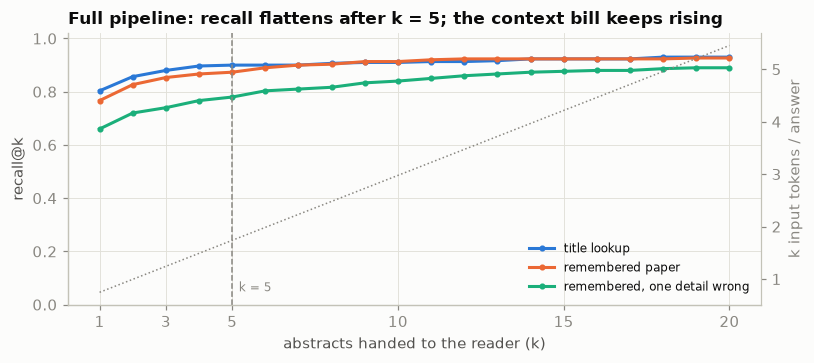

,title lookup,remembered paper,"remembered, one detail wrong",input tokens / answer,€ / answer,€ / week
1,0.80,0.77,0.66,748,0.0049,0.97
3,0.88,0.85,0.74,"1,243",0.0061,1.22
5,0.90,0.87,0.78,"1,738",0.0073,1.47
10,0.91,0.91,0.84,"2,977",0.0104,2.09
20,0.93,0.93,0.89,"5,453",0.0166,3.33


abstracts average 183 words ≈ 248 tokens


In [15]:
# ---- the operating point: how many abstracts to hand the generation step ----
ks = np.arange(1, 21)
words = idx.abstract.str.count(r"\S+")
tokens_per_abstract = words.mean() * TOKENS_PER_WORD
curve = pd.DataFrame({fam: [(RANKS_KB[PIPELINE][gold.family.values == fam] <= k).mean() for k in ks] for fam in FAMILIES}, index=ks)
cost = pd.DataFrame({"input tokens / answer": PROMPT_OVERHEAD_TOKENS + ks * tokens_per_abstract}, index=ks)
cost["€ / answer"] = cost["input tokens / answer"] / 1e6 * EUR_PER_M_INPUT + ANSWER_TOKENS / 1e6 * EUR_PER_M_OUTPUT
cost["€ / week"] = cost["€ / answer"] * QUESTIONS_PER_WEEK

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for fam, col in zip(FAMILIES, SERIES):
    ax.plot(ks, curve[fam], "-o", ms=3, lw=2, color=col, label=fam)
ax.axvline(K, color=MUTED, ls="--", lw=1); ax.text(K + 0.2, 0.05, f"k = {K}", color=MUTED, fontsize=8)
ax.set_ylim(0, 1.02); ax.set_xticks([1, 3, 5, 10, 15, 20]); ax.set_xlabel("abstracts handed to the reader (k)"); ax.set_ylabel("recall@k")
ax2 = ax.twinx(); ax2.plot(ks, cost["input tokens / answer"] / 1e3, color=MUTED, lw=1, ls=":"); ax2.set_ylabel("k input tokens / answer", color=MUTED)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_title("Full pipeline: recall flattens after k = 5; the context bill keeps rising"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
display(pd.concat([curve, cost], axis=1).loc[[1, 3, 5, 10, 20]].style.format(
    {**{f: "{:.2f}" for f in FAMILIES}, "input tokens / answer": "{:,.0f}", "€ / answer": "{:.4f}", "€ / week": "{:.2f}"}))
print(f"abstracts average {words.mean():.0f} words ≈ {tokens_per_abstract:.0f} tokens")

At *k* = 5 the full pipeline finds 90 % of title questions, 87 % of remembered papers and 78 % with a detail wrong, with about 1,740 input tokens: €0.007 an answer, €1.47 a week at 200 questions. Doubling *k* buys one to six points for 70 % more context.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test (forward split, golden-set leakage, upsert, author keys).*

Four shortcuts a careless version would take, each measured against the honest number.

**Trap 1 — one label per paper, and the random split.** Predicting one category per paper gives micro-F1 0.614 and macro-F1 0.176 against 0.722 and 0.530 (Section 3). The random split surprises: 0.706 against 0.707 forward. Over eighteen months it inflates nothing; time costs show only forward (Section 7).

**Trap 2 — golden-set leakage.** Generated questions carry their source text. Against an index that also holds titles, title-question recall@1 jumps from 0.80 to 0.99, and remembered papers rise from 0.36 to 0.64 because their three words came from the title. Never score a golden set against its own source field; the same holds for the KB (Section 5).

**Trap 3 — versions and duplicates.** Of papers first posted July – December 2024, 15 % had a newer version within 30 days, 23 % within 90 and 42 % within a year: an unversioned citation then points at another text. The weekly file also re-delivers: 41 % of the 15,572 records updated in its last week were older papers, mostly revised. A simulated append-only ingestion (later versions re-added as identical rows) adds 34,902 rows (40 %); 68 % of golden top-5 lists then hold one paper twice. Upsert by id; cite id and version.

**Trap 4 — author-name ambiguity.** A surname-plus-initial key merges people: 64 % of authorships sit on a key covering two or more different full forenames (an upper bound: one person may spell a forename two ways). "Other papers by this first author" returns 59,453 papers for the 300 golden papers under that key and 1,552 under the full name (median 13 against 2); in the cs.IR co-author graph it folds 18,765 full-name keys into 10,225 nodes, 68 % in one component. Full names under-merge instead (task E2).

In [16]:
# Trap 1 — the random split: same model, same training size, same 0.5 rule; only the split changes
lab_rows = np.flatnonzero(period != "stream")                       # Jul 2024 – Dec 2025
r_tr, r_te = train_test_split(lab_rows, train_size=N_TRAIN, test_size=len(te), random_state=SEED)
df_r = np.bincount(C_all[r_tr].indices, minlength=C_all.shape[1]); keep_r = np.flatnonzero(df_r >= 5)
tf_r = TfidfTransformer(sublinear_tf=True).fit(C_all[r_tr][:, keep_r])
clf_r = OneVsRestClassifier(SGDClassifier(loss="log_loss", alpha=2e-5, max_iter=20, tol=None, random_state=SEED), n_jobs=N_JOBS)
clf_r.fit(tf_r.transform(C_all[r_tr][:, keep_r]), Y[r_tr])
P_r = clf_r.predict_proba(tf_r.transform(C_all[r_te][:, keep_r]))
trap1 = pd.DataFrame({
    "random 70/30 over Jul 2024 – Dec 2025 ⚠": [f1_score(Y[r_te], P_r >= 0.5, average=a, zero_division=0) for a in ("micro", "macro")],
    "forward: train to Jun 2025, test Oct–Dec 2025": [f1_score(Y[te], P_te >= 0.5, average=a, zero_division=0) for a in ("micro", "macro")],
}, index=["micro-F1", "macro-F1"]).T
display(trap1.style.format("{:.3f}"))

# Trap 2 — golden-set leakage: the title questions against an index that also holds the titles
W_leak = bm25_weights(C_all[in_idx])
leak = pd.concat({"index: abstracts only (honest)": summarise(RANKS["BM25 · abstracts"], gold),
                  "index: title + abstract ⚠": summarise(ranks_of(bm25_fn(W_leak), gold), gold)}, names=["index", "family"])
del W_leak
display(leak.unstack("family").style.format("{:.2f}"))

,micro-F1,macro-F1
random 70/30 over Jul 2024 – Dec 2025 ⚠,0.706,0.383
"forward: train to Jun 2025, test Oct–Dec 2025",0.707,0.388


In [17]:
# Trap 3 — versions and duplicates
cohort = lag[(lag.v1 >= SAMPLE_START) & (lag.v1 < SAMPLE_START + pd.DateOffset(months=6))]       # ≥ 21 months of history
v2_days = cohort.v2_days.to_numpy()
days = np.array([7, 30, 90, 180, 365, 540])
stale = pd.Series([(v2_days <= d).mean() for d in days], index=[f"{d} days" for d in days])
print(f"papers first posted {SAMPLE_START:%b}–{(SAMPLE_START + pd.DateOffset(months=5)):%b %Y} ({len(cohort):,}): share with a newer version "
      f"than v1 after …", (stale * 100).round(1).to_dict())

is_new = week_rec.v1 >= newest - pd.Timedelta(days=8)
print(f"records with update_date in the snapshot's last 7 days: {len(week_rec):,}; first posted before that week: {(~is_new).sum():,} "
      f"({(~is_new).mean():.0%}), of which with a new version in the week: {((~is_new) & (week_rec.vlast >= newest - pd.Timedelta(days=8))).sum():,}")

# simulated: an append-only weekly ingestion that adds one more copy of a paper per extra version (identical text: the best case)
dup_rows = np.repeat(np.arange(len(idx)), n_ver - 1)
W_dup = sp.vstack([W_abs, W_abs[dup_rows]]).tocsr()
owner = np.r_[np.arange(len(idx)), dup_rows]
def distinct_in_top(W, qs, k=K):
    out = []
    for s, S in scores(W, counts.transform, qs.question.tolist()):
        top = np.argpartition(-S, k, axis=0)[:k]
        out += [len(set(owner[top[:, j]])) for j in range(S.shape[1])]
    return np.array(out)
d_top = distinct_in_top(W_dup, gold); del W_dup
title_dups = idx.title.str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip().duplicated(keep=False)
print(f"append-only index: {len(dup_rows):,} extra rows ({len(dup_rows)/len(idx):.0%}); top-{K} lists holding a paper twice: "
      f"{(d_top < K).mean():.0%}, distinct papers per top-{K}: {d_top.mean():.2f} (upsert by id: {K})")
print(f"different arXiv ids with the same normalised title in the index: {title_dups.sum()} papers")

papers first posted Jul–Dec 2024 (28,515): share with a newer version than v1 after … {'7 days': 8.4, '30 days': 14.8, '90 days': 22.6, '180 days': 33.2, '365 days': 42.0, '540 days': 44.6}
records with update_date in the snapshot's last 7 days: 15,572; first posted before that week: 6,424 (41%), of which with a new version in the week: 4,993


append-only index: 34,902 extra rows (40%); top-5 lists holding a paper twice: 68%, distinct papers per top-5: 4.01 (upsert by id: 5)
different arXiv ids with the same normalised title in the index: 28 papers


In [18]:
# Trap 4 — author-name ambiguity: the same string, different people (and the same person, different strings)
full = authorship[~authorship.initials_only & (fn.str.len() >= 3)]
names_per_naive = full.groupby("key_naive").key_strict.nunique()
merged_keys = names_per_naive[names_per_naive >= 2].index
share_rows = authorship.key_naive.isin(merged_keys).mean()
print(f"surname + initial keys covering ≥ 2 different full forenames: {len(merged_keys):,} "
      f"({share_rows:.0%} of all authorships sit on such a key); initials-only forenames: {authorship.initials_only.mean():.1%} of authorships")

def coauthor_graph(key):
    ir = categories[categories.category == "cs.IR"].id
    a = authorship[authorship.id.isin(ir)]
    G = nx.Graph()
    for _, grp in a.groupby("id")[key]:
        ks_ = grp.unique().tolist(); G.add_nodes_from(ks_)
        G.add_edges_from((ks_[i], ks_[j]) for i in range(len(ks_)) for j in range(i + 1, len(ks_)))
    giant = max(nx.connected_components(G), key=len)
    return {"authors (nodes)": G.number_of_nodes(), "co-author edges": G.number_of_edges(),
            "largest component": len(giant), "largest component share": len(giant) / G.number_of_nodes()}
trap4 = pd.DataFrame({"surname + first initial ⚠": coauthor_graph("key_naive"), "surname + full forename": coauthor_graph("key_strict")}).T
display(trap4.style.format({"authors (nodes)": "{:,.0f}", "co-author edges": "{:,.0f}", "largest component": "{:,.0f}", "largest component share": "{:.1%}"}))

# 'more by this author': expand from each golden paper's first author
first = authorship[(authorship.pos == 0) & authorship.id.isin(idx.id[gold.target[rem]])]
more_naive = first.key_naive.map(authorship.groupby("key_naive").id.nunique()) - 1
more_strict = first.key_strict.map(authorship.groupby("key_strict").id.nunique()) - 1
print(f"'other papers by this first author' for {len(first)} golden papers: naive key {more_naive.sum():,} papers, "
      f"strict key {more_strict.sum():,}; median {more_naive.median():.0f} vs {more_strict.median():.0f}")
del full, W_flat, T_abs; con.close()

surname + initial keys covering ≥ 2 different full forenames: 13,526 (64% of all authorships sit on such a key); initials-only forenames: 0.5% of authorships


,authors (nodes),co-author edges,largest component,largest component share
surname + first initial ⚠,"10,225","101,478","6,940",67.9%
surname + full forename,"18,765","118,082","11,230",59.8%


'other papers by this first author' for 300 golden papers: naive key 59,453 papers, strict key 1,552; median 13 vs 2


# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the feed moves every week

*Part C · Productionise · what your monitoring plan must catch: volume, cross-listing, unseen terms and router decay (C5).*

The router stays frozen at its June 2025 cut and runs month by month to September 2026, beside three label-free signals: volume, cross-listing shares and the share of tokens it has never seen. Labels arrive with the paper, so quality is measurable the same week; moderators' later changes, the only label delay, are invisible in one snapshot.

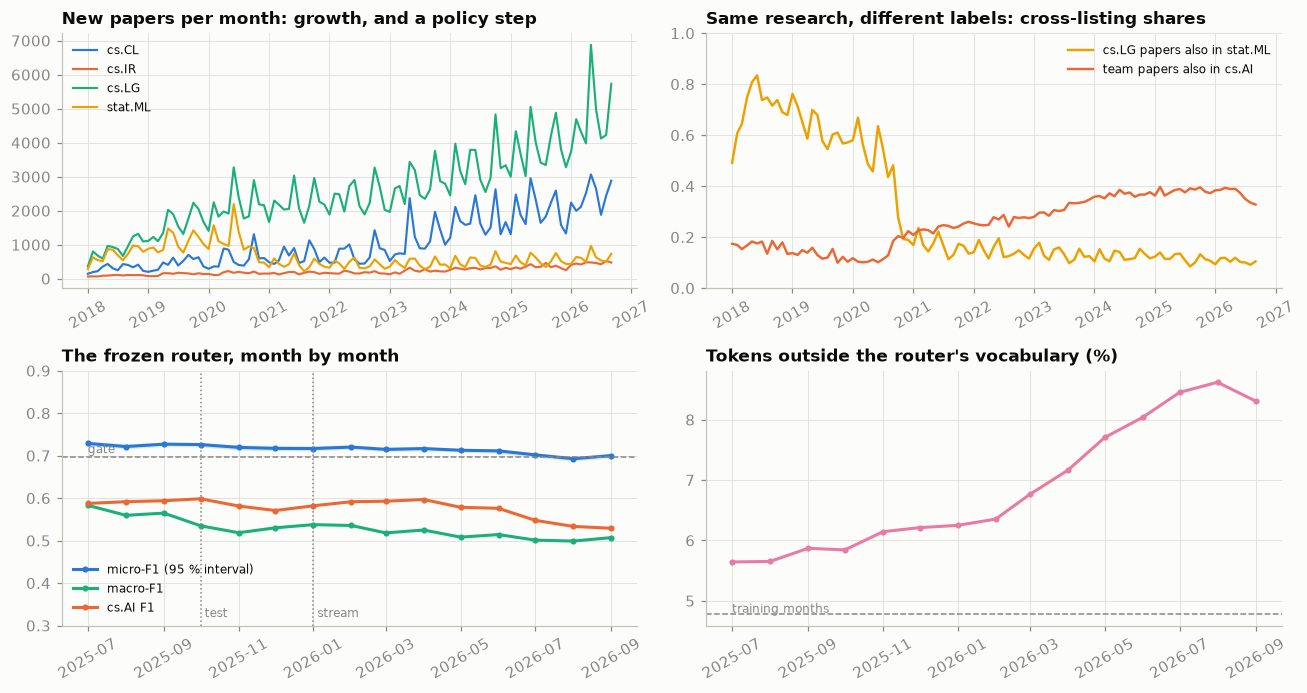

,papers,micro-F1,low,high,macro-F1,cs.AI F1,cs.AI share (true),cs.AI share (predicted),unseen-term share
month,,,,,,,,,
2025-07,"4,963",0.729,0.723,0.735,0.583,0.588,37.6%,70.4%,5.64%
2025-08,"5,094",0.721,0.716,0.728,0.560,0.592,39.1%,73.3%,5.65%
2025-09,"6,214",0.727,0.721,0.732,0.565,0.594,38.7%,72.3%,5.87%
2025-10,"7,179",0.726,0.721,0.731,0.535,0.598,39.5%,71.5%,5.84%
2025-11,"5,323",0.719,0.714,0.725,0.519,0.581,37.8%,69.6%,6.14%
2025-12,"4,518",0.717,0.711,0.723,0.530,0.571,37.3%,67.9%,6.21%
2026-01,"5,806",0.717,0.711,0.723,0.538,0.582,38.3%,72.0%,6.25%
2026-02,"6,488",0.720,0.715,0.726,0.536,0.591,38.5%,69.9%,6.35%
2026-03,"6,313",0.715,0.710,0.720,0.518,0.593,39.3%,68.9%,6.76%


gate (validation micro-F1 − 0.03) = 0.696; months below it: ['2026-08'], of which with the whole interval below: []; months whose interval reaches below the gate: ['2026-08', '2026-09']; unseen-term share on the training rows 4.8%
team papers a month: 628 (2018-01) → 8,271 (2026-09) · cs.LG papers also in stat.ML: 0.64 (2020-06) → 0.28 (2020-10) → 0.17 (2021-01) · team papers also in cs.AI: 12% (2020-01) → 38% (2026-01) → 33% (2026-09)
176 categories in the snapshot; first used on or after 1 Jan 2019: none


In [19]:
# ---- the long view (monthly, stat_share, ai_share) was aggregated from the census in Section 2 ----

# ---- the frozen router, month by month, from validation to the last complete month ----
mon = team.v1.dt.to_period("M").to_numpy()
months = pd.period_range(TRAIN_END.to_period("M"), (LAST_V1.to_period("M") - 1), freq="M")
gate = f1_score(Y[va], P_va >= thr_label, average="micro") - GATE_TOLERANCE   # derived from validation, never from test
drift_rows, ci_rng = [], np.random.default_rng(SEED)
for m in months:
    rows_m = np.flatnonzero(mon == m)
    P_m = router.predict_proba(features(rows_m))
    pred = P_m >= thr_label
    toks = C_all[rows_m]
    y_m = Y[rows_m] == 1                                     # micro-F1 interval: resample papers within the month
    tp, fp, fn = (pred & y_m).sum(1), (pred & ~y_m).sum(1), (~pred & y_m).sum(1)
    b = ci_rng.integers(0, len(rows_m), (500, len(rows_m)))
    lo_, hi_ = np.percentile(2 * tp[b].sum(1) / (2 * tp[b].sum(1) + fp[b].sum(1) + fn[b].sum(1)), [2.5, 97.5])
    drift_rows.append({"month": m, "papers": len(rows_m), "micro-F1": f1_score(Y[rows_m], pred, average="micro"), "low": lo_, "high": hi_,
                       "macro-F1": f1_score(Y[rows_m], pred, average="macro", zero_division=0),
                       "cs.AI F1": f1_score(Y[rows_m, LABELS.index("cs.AI")], pred[:, LABELS.index("cs.AI")]),
                       "cs.AI share (true)": Y[rows_m, LABELS.index("cs.AI")].mean(), "cs.AI share (predicted)": pred[:, LABELS.index("cs.AI")].mean(),
                       "unseen-term share": 1 - toks[:, KEEP].sum() / toks.sum()})
drift = pd.DataFrame(drift_rows).set_index("month")
train_oov = 1 - C_all[tr][:, KEEP].sum() / C_all[tr].sum()

fig, axes = plt.subplots(2, 2, figsize=(12, 6.4))
ax = axes[0, 0]
for c, col in zip(TEAM_CATS, SERIES):
    ax.plot(monthly.index.to_timestamp(), monthly[c], color=col, lw=1.4, label=c)
ax.set_title("New papers per month: growth, and a policy step"); ax.legend(fontsize=8)
ax = axes[0, 1]
ax.plot(stat_share.index.to_timestamp(), stat_share, color=SERIES[3], lw=1.6, label="cs.LG papers also in stat.ML")
ax.plot(ai_share.index.to_timestamp(), ai_share, color=SERIES[1], lw=1.6, label="team papers also in cs.AI")
ax.set_ylim(0, 1); ax.set_title("Same research, different labels: cross-listing shares"); ax.legend(fontsize=8)
ax = axes[1, 0]
t_ = drift.index.to_timestamp()
ax.fill_between(t_, drift.low, drift.high, color=SERIES[0], alpha=0.15, lw=0)
ax.plot(t_, drift["micro-F1"], "-o", ms=3, lw=2, color=SERIES[0], label="micro-F1 (95 % interval)")
ax.plot(t_, drift["macro-F1"], "-o", ms=3, lw=2, color=SERIES[2], label="macro-F1")
ax.plot(t_, drift["cs.AI F1"], "-o", ms=3, lw=2, color=SERIES[1], label="cs.AI F1")
ax.axhline(gate, color=MUTED, ls="--", lw=1); ax.text(t_[0], gate + 0.01, "gate", color=MUTED, fontsize=8)
for x_, lab_ in [(VALID_END, "test"), (TEST_END, "stream")]:
    ax.axvline(x_, color=MUTED, ls=":", lw=1); ax.text(x_, 0.32, f" {lab_}", color=MUTED, fontsize=8)
ax.set_ylim(0.3, 0.9); ax.set_title("The frozen router, month by month"); ax.legend(fontsize=8, loc="lower left")
ax = axes[1, 1]
ax.plot(t_, drift["unseen-term share"] * 100, "-o", ms=3, lw=2, color=SERIES[4])
ax.axhline(train_oov * 100, color=MUTED, ls="--", lw=1); ax.text(t_[0], train_oov * 100 + 0.02, "training months", color=MUTED, fontsize=8)
ax.set_title("Tokens outside the router's vocabulary (%)")
for a in axes.ravel():
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
display(drift.style.format({"papers": "{:,}", "micro-F1": "{:.3f}", "low": "{:.3f}", "high": "{:.3f}", "macro-F1": "{:.3f}", "cs.AI F1": "{:.3f}",
                                      "cs.AI share (true)": "{:.1%}", "cs.AI share (predicted)": "{:.1%}", "unseen-term share": "{:.2%}"}))
print(f"gate (validation micro-F1 − {GATE_TOLERANCE}) = {gate:.3f}; months below it: {[str(m) for m in drift.index[drift['micro-F1'] < gate]]}, "
      f"of which with the whole interval below: {[str(m) for m in drift.index[drift.high < gate]]}; "
      f"months whose interval reaches below the gate: {[str(m) for m in drift.index[drift.low < gate]]}; "
      f"unseen-term share on the training rows {train_oov:.1%}")
print(f"team papers a month: {monthly.team.iloc[0]:,} ({monthly.index[0]}) → {monthly.team.iloc[-1]:,} ({monthly.index[-1]}) · "
      f"cs.LG papers also in stat.ML: {stat_share['2020-06']:.2f} (2020-06) → {stat_share['2020-10']:.2f} (2020-10) → {stat_share['2021-01']:.2f} (2021-01) · "
      f"team papers also in cs.AI: {ai_share['2020-01']:.0%} (2020-01) → {ai_share['2026-01']:.0%} (2026-01) → {ai_share.iloc[-1]:.0%} ({ai_share.index[-1]})")
print(f"{len(first_seen)} categories in the snapshot; first used on or after 1 Jan 2019: "
      f"{list(first_seen[first_seen >= '2019-01-01'].index) or 'none'}")

In [20]:
# ---- new vocabulary: terms whose document frequency grew most since the training year ----
late = np.flatnonzero((mon >= (LAST_V1.to_period("M") - 3)) & (mon < LAST_V1.to_period("M")))    # last three complete months
dfr = lambda rows: np.bincount(C_all[rows].indices, minlength=C_all.shape[1]) / len(rows)
d_tr, d_late = dfr(tr), dfr(late)
ok = np.flatnonzero(d_late * len(late) >= 40)
terms = list(counts.vocab)
rise = pd.DataFrame({"term": [terms[i] for i in ok], "share of papers, training year": d_tr[ok], "share, last 3 months": d_late[ok]})
rise["ratio"] = (rise["share, last 3 months"] + 1e-4) / (rise["share of papers, training year"] + 1e-4)
display(rise.sort_values("ratio", ascending=False).head(12).set_index("term").style.format(
    {"share of papers, training year": "{:.2%}", "share, last 3 months": "{:.2%}", "ratio": "{:.1f}×"}))

,"share of papers, training year","share, last 3 months",ratio
term,,,
survives,0.01%,1.00%,60.5×
opd,0.00%,0.66%,50.3×
qwen3,0.03%,1.58%,43.3×
audited,0.01%,0.65%,39.4×
recoverable,0.01%,0.69%,35.2×
qwen3-8b,0.01%,0.64%,32.3×
buys,0.00%,0.29%,29.9×
auditable,0.03%,1.09%,29.9×
declared,0.01%,0.57%,29.0×


Read the panels together. Volume grew thirteen-fold since 2018 (628 team papers in January 2018, 8,271 in September 2026): alert on a z-score against the trailing quarter. Labels move, research does not: the stat.ML share of cs.LG papers fell from 0.64 (June 2020) to 0.17 (January 2021), a change in cross-listing practice; the cs.AI share rose from 12 % (January 2020) to 38 % (January 2026), then fell to 33 %. From the first test month the frozen router decays slowly (micro-F1 0.726 → 0.693 by August 2026, macro-F1 0.535 → 0.499, cs.AI F1 0.60 → 0.53) while unseen tokens climb from 4.8 % to 8.6 %. The gate (validation − 0.03, an assumption) is crossed once, in August 2026, within noise (0.687–0.698 against 0.696; September's interval also dips below): trigger on two such months. What the router barely saw in training (0.01–0.03 % of training papers, 0.6–1.6 % in the last three months): model names (`qwen3`, `qwen3-8b`) and phrasing (`survives`, `auditable`, `recoverable`). No category is new since 2019.

**The answer to the board.** Route: yes, but routing alone hands the cs.IR reader four times what one person reads, cs.LG sixty times. Find: in the top five, nine title questions in ten and 87 % of remembered papers when author and year are right, 78 % with one detail wrong. Trust: only with version-pinned citations and a claim check that still rejects one honest paraphrase in six. Running it is cheap; the upkeep is the weekly upsert, the author keys and a monthly retraining check.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles with this notebook's numbers. Card corrections: the drift is vocabulary, cross-listing and volume, not new categories (none since 2019); "embedding drift" becomes the unseen-term share until E1.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/research_assistant/` (`ingest` with upsert by id, `route`, `index`, `ask`); `POST /ask` plus a weekly job; Postgres with the edge tables (Neo4j in E3); no PDF store; 86,766 abstracts, 8.2 M postings |
| Monitoring (S04) | Weekly: papers ingested (1,189–3,091 in 2026: a z-score alert), share re-delivered (41 %), unseen-term share (4.8 % → 8.6 %), predicted against true cs.AI share. Per answer: versioned citations, verifier rejections, unanswered questions, cost (€0.007 at *k* = 5) |
| CI/CD gate (S05) | Router micro-F1 on the latest frozen month ≥ 0.696 (validation − 0.03, an assumption), judged with its bootstrap interval; golden-set recall@5 per family (0.90, 0.87, 0.78 today; set the bars on the August dev set); refuse if the snapshot MD5 (`a1d67fb3…`) or the golden set's SHA-256 (`61dd0dd7…`) changes |
| MLflow tracking and registry (S06) | Kaggle version and MD5, sampling and split dates, thresholds, router F1s, BM25 parameters, year and category weights, τ, golden-set scores; `champion` aliases |
| Offline / online training and serving | Offline, weekly: stream (eleven minutes here), upsert, re-route, re-index (S2 makes it incremental). Online: `/ask` over a sparse BM25 matrix. Retrain monthly, or after two months below the gate |
| Data and model drift | Volume ×13 since 2018; stat.ML share of cs.LG 0.64 → 0.17 (2020); cs.AI share 38 % → 33 % (2026); frozen router micro-F1 0.726 → 0.693, macro-F1 0.535 → 0.499; new terms |
| Knowledge base and context (S07–S09) | Graph of 86,766 papers, 121,668 versions, 423,626 authorships, 185,139 category edges. Ablation, recall@1 remembered exactly / one detail wrong: 0.36 / 0.36 (BM25) → 0.66 / 0.58 (names as text) → 0.77 / 0.66 (graph); a year filter falls to 0.41 with a detail wrong |
| GenAI and context engineering (S10–S11) | Cited answers from the top five abstracts, citations with versions; every claim through `verify_claim` (τ = 0.55: accepts 83 % of papers' own titles, 8.7 % of runner-up titles, 6 % of changed numbers, 9 % of negations); golden-set regression; cost per answer |
| Governance | Metadata CC0, full texts not (37 % arXiv's non-exclusive licence, 11 % non-commercial): no PDFs ingested. Authors' names are personal data even in a CC0 file: linking only, never printed. EU AI Act position (our reading: not an Annex III use): task E4 |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch task is optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** Forward splits only; golden questions never scored against their own text; upsert by id, keeping versions; author keys that never merge different full forenames; a tested `cite_version(id, date)`.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary reading capacity, per-category thresholds, *k*, prices and question volume; record the choice in an ADR.
- **C4 — Package, container and CI gate.** `ingest`, `route`, `index`, `ask` in `src/research_assistant/`; `POST /ask` in a container; `make ci` gates on router micro-F1 (latest frozen month) and recall@5 per family, refusing a changed snapshot MD5 or golden-set SHA-256 (Sessions 02, 03, 05).
- **C5 — Track, register, document, monitor.** MLflow runs with the Kaggle version, MD5 and metrics; a `champion` alias; a model card (author-assigned labels, aliases, versions, licences); a monitoring plan with the Section 7 signals and the retraining trigger (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** Add dense vectors (sentence-transformers); compare vector RAG, BM25 and Graph-RAG, with and without KB context, on all three families and your own questions (Sessions 07–09).
- **E2 — Author disambiguation.** Split surname-plus-initial keys with co-authors and vocabulary; evaluate on 100 hand-labelled keys.
- **E3 — Shapes and competency questions.** Export the graph to RDF, turn the contract checks into SHACL shapes and answer CQ1–CQ3 in SPARQL or Cypher.
- **E4 — Governance.** For each licence: may you store, quote or summarise the full text? Then the GDPR position on authors' names in a CC0 file and the EU AI Act position, as your reading.

### Stretch

- **S1 — The GenAI component.** An LLM answers from the top-*k* abstracts behind a versioned prompt returning `{answer, claims: [{text, cite}]}`; every claim passes `verify_claim` and an NLI or judge model; evaluate citation accuracy, unsupported claims, refusals, injections and cost (Sessions 10–11).
- **S2 — Streaming ingestion and online serving.** Diff two weekly snapshots; upsert, re-route and re-index incrementally; report freshness, weekly cost and `/ask` latency.
- **S3 — What matters to *this* team.** Collect two weeks of relevance judgements, report precision at reading capacity per category, and decide in an ADR whether a personal profile is worth its data-protection cost (no recommender required).

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; Kaggle version and MD5 recorded
- [ ] `README.md`: sampling rule, split dates, index window, how to get the data (CC0 metadata, no full texts)
- [ ] Forward evaluation only; traps removed with tests (split, leakage, upsert by id, author keys)
- [ ] Thresholds and context size chosen from capacity and cost, with ADRs
- [ ] CI with router and golden-set gates; registered model, model card, monitoring plan
- [ ] Knowledge-base ablation table; licence and personal-data position
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `rank-bm25`, `networkx`, `duckdb`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- Cornell University, *arXiv Dataset* (Kaggle), version 309; Clement, C. B. et al. (2019). *On the Use of ArXiv as a Dataset.* arXiv:1905.00075.
- Robertson, S., Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in IR.
- Cormack, G. V., Clarke, C. L. A., Buettcher, S. (2009). *Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods.* SIGIR.
- Tsoumakas, G., Katakis, I. (2007). *Multi-Label Classification: An Overview.* IJDWM.
- Smalheiser, N. R., Torvik, V. I. (2009). *Author Name Disambiguation.* ARIST 43.
- Huyen, C. (2024). *AI Engineering*, Ch. 4 (evaluation) and Ch. 6 (RAG).

In [21]:
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

notebook finished · total wall time 142s
